# New Car Price Prediction Using Statistical Inference and Machine Learning

**Project:** New Car Price Prediction  
**Dataset:** `cars_ds_final.csv`  
**Target:** `Ex-Showroom_Price` (new-car ex-showroom price in INR)

## Project aim
Analyze new-car ex-showroom prices and their relationship with car specifications, apply statistical inference and regression techniques, compare regression models, and save a trained model for use in a Streamlit application.

**Dataset note:** This notebook is adapted for the uploaded Indian Cars dataset containing new-car models and variants. It predicts the historical ex-showroom prices recorded in the dataset; it does not predict used-car resale prices or current live showroom quotations.

**Workflow:** Google Colab is used for data cleaning, statistical analysis, model training, evaluation, and exporting the trained model. VS Code + Streamlit is used for the frontend.


## 1. Import libraries and load the dataset

**What we use**
- `pandas` and `numpy`: read and process the dataset.
- `matplotlib` and `seaborn`: draw graphs.
- `scipy.stats`: statistical tests and confidence intervals.
- `scikit-learn`: preprocess data, train regression models, and evaluate predictions.
- `joblib` and `json`: save the trained model and input configuration.

Upload the file named `cars_ds_final.csv` when Colab asks for it.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import os
import re
import sklearn

from scipy import stats
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

# Load the uploaded new-car dataset
DATA_FILE = "cars_ds_final.csv"

if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("Please upload cars_ds_final.csv")
    DATA_FILE = csv_files[0]

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing count"))
print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)


Saving cars_ds_final.csv to cars_ds_final.csv
Dataset shape: (1276, 141)

Column names:
['Unnamed: 0', 'Make', 'Model', 'Variant', 'Ex-Showroom_Price', 'Displacement', 'Cylinders', 'Valves_Per_Cylinder', 'Drivetrain', 'Cylinder_Configuration', 'Emission_Norm', 'Engine_Location', 'Fuel_System', 'Fuel_Tank_Capacity', 'Fuel_Type', 'Height', 'Length', 'Width', 'Body_Type', 'Doors', 'City_Mileage', 'Highway_Mileage', 'ARAI_Certified_Mileage', 'ARAI_Certified_Mileage_for_CNG', 'Kerb_Weight', 'Gears', 'Ground_Clearance', 'Front_Brakes', 'Rear_Brakes', 'Front_Suspension', 'Rear_Suspension', 'Front_Track', 'Rear_Track', 'Front_Tyre_&_Rim', 'Rear_Tyre_&_Rim', 'Power_Steering', 'Power_Windows', 'Power_Seats', 'Keyless_Entry', 'Power', 'Torque', 'Odometer', 'Speedometer', 'Tachometer', 'Tripmeter', 'Seating_Capacity', 'Seats_Material', 'Type', 'Wheelbase', 'Wheels_Size', 'Start_/_Stop_Button', '12v_Power_Outlet', 'Audiosystem', 'Aux-in_Compatibility', 'Average_Fuel_Consumption', 'Basic_Warranty', 

,Unnamed: 0,Make,Model,Variant,Ex-Showroom_Price,Displacement,Cylinders,Valves_Per_Cylinder,Drivetrain,Cylinder_Configuration,...,Leather_Wrapped_Steering,Automatic_Headlamps,Engine_Type,ASR_/_Traction_Control,Cruise_Control,USB_Ports,Heads-Up_Display,Welcome_Lights,Battery,Electric_Range
0,0,Tata,Nano Genx,Xt,"Rs. 2,92,667",624 cc,2.0,2.0,RWD (Rear Wheel Drive),In-line,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Tata,Nano Genx,Xe,"Rs. 2,36,447",624 cc,2.0,2.0,RWD (Rear Wheel Drive),In-line,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,Tata,Nano Genx,Emax Xm,"Rs. 2,96,661",624 cc,2.0,2.0,RWD (Rear Wheel Drive),In-line,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,Tata,Nano Genx,Xta,"Rs. 3,34,768",624 cc,2.0,2.0,RWD (Rear Wheel Drive),In-line,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,Tata,Nano Genx,Xm,"Rs. 2,72,223",624 cc,2.0,2.0,RWD (Rear Wheel Drive),In-line,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,Missing count
Unnamed: 0,0
Make,75
Model,0
Variant,0
Ex-Showroom_Price,0
...,...
USB_Ports,1247
Heads-Up_Display,1225
Welcome_Lights,1207
Battery,1263



Duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1276.0,NaN,NaN,NaN,637.5,368.493781,0.0,318.75,637.5,956.25,1275.0
Make,1201,39,Maruti Suzuki,149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,1276,263,Nexon,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Variant,1276,1064,Lxi,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ex-Showroom_Price,1276,1179,"Rs. 9,99,900",14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
USB_Ports,29.0,NaN,NaN,NaN,1.793103,0.773642,1.0,1.0,2.0,2.0,3.0
Heads-Up_Display,51,1,Yes,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Welcome_Lights,69,1,Yes,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Battery,13,5,"21.5 kWh,Battery Placed Under Rear Seats",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Check data quality and clean the dataset

- Remove duplicate records.
- Remove the exported index column `Unnamed: 0` if present.
- Convert `Ex-Showroom_Price` from text such as `Rs. 2,92,667` into a numeric INR value.
- Keep rows with a valid, positive ex-showroom price.
- Select useful new-car specifications for prediction.
- Convert numeric specifications containing units (for example, `624 cc`, `1652 mm`, or `38PS@5500rpm`) into numeric values.

**Target column:** `Ex-Showroom_Price`. This is the new-car ex-showroom price in the supplied dataset.


In [2]:
print("Missing values before cleaning:")
display(df.isnull().sum().to_frame("Missing count"))
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

target = "Ex-Showroom_Price"

if target not in df.columns:
    raise ValueError("The dataset must contain an 'Ex-Showroom_Price' column.")

# Convert prices such as 'Rs. 2,92,667' into numeric INR values.
df[target] = (
    df[target].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("Rs.", "", regex=False)
    .str.extract(r"(\d+(?:\.\d+)?)")[0]
)
df[target] = pd.to_numeric(df[target], errors="coerce")

df = df.dropna(subset=[target])
df = df[df[target] > 0].copy()

# Use meaningful car specifications available in this dataset.
numeric_candidates = [
    "Displacement", "Cylinders", "Valves_Per_Cylinder",
    "Fuel_Tank_Capacity", "Height", "Length", "Width", "Doors",
    "City_Mileage", "Highway_Mileage", "ARAI_Certified_Mileage",
    "Kerb_Weight", "Gears", "Ground_Clearance", "Power", "Torque",
    "Seating_Capacity", "Wheelbase", "Boot_Space",
    "Number_of_Airbags", "Electric_Range"
]

categorical_candidates = [
    "Make", "Model", "Variant", "Fuel_Type", "Body_Type",
    "Type", "Drivetrain", "Cylinder_Configuration", "Emission_Norm"
]

numeric_features = [
    col for col in numeric_candidates
    if col in df.columns and df[col].notna().any()
]
categorical_features = [
    col for col in categorical_candidates
    if col in df.columns and df[col].notna().any()
]

# Extract the first numeric value from specifications that include units.
# Examples: '624 cc' -> 624, '23.6 km/litre' -> 23.6,
# '38PS@5500rpm' -> 38, and '51Nm@4000rpm' -> 51.
for col in numeric_features:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r"([-+]?\d*\.?\d+)")[0],
        errors="coerce"
    )

features = numeric_features + categorical_features
if not features:
    raise ValueError("No usable car specification columns were found.")

X = df[features].copy()
y = df[target].copy()

print("Rows after cleaning:", len(df))
print("Selected features:", features)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nMissing feature values:")
display(X.isnull().sum().to_frame("Missing count"))


Missing values before cleaning:


,Missing count
Unnamed: 0,0
Make,75
Model,0
Variant,0
Ex-Showroom_Price,0
...,...
USB_Ports,1247
Heads-Up_Display,1225
Welcome_Lights,1207
Battery,1263


Duplicate rows before cleaning: 0
Rows after cleaning: 1276
Selected features: ['Displacement', 'Cylinders', 'Valves_Per_Cylinder', 'Fuel_Tank_Capacity', 'Height', 'Length', 'Width', 'Doors', 'City_Mileage', 'Highway_Mileage', 'ARAI_Certified_Mileage', 'Kerb_Weight', 'Gears', 'Ground_Clearance', 'Power', 'Torque', 'Seating_Capacity', 'Wheelbase', 'Boot_Space', 'Number_of_Airbags', 'Electric_Range', 'Make', 'Model', 'Variant', 'Fuel_Type', 'Body_Type', 'Type', 'Drivetrain', 'Cylinder_Configuration', 'Emission_Norm']
Numeric features: ['Displacement', 'Cylinders', 'Valves_Per_Cylinder', 'Fuel_Tank_Capacity', 'Height', 'Length', 'Width', 'Doors', 'City_Mileage', 'Highway_Mileage', 'ARAI_Certified_Mileage', 'Kerb_Weight', 'Gears', 'Ground_Clearance', 'Power', 'Torque', 'Seating_Capacity', 'Wheelbase', 'Boot_Space', 'Number_of_Airbags', 'Electric_Range']
Categorical features: ['Make', 'Model', 'Variant', 'Fuel_Type', 'Body_Type', 'Type', 'Drivetrain', 'Cylinder_Configuration', 'Emission_Nor

,Missing count
Displacement,12
Cylinders,66
Valves_Per_Cylinder,102
Fuel_Tank_Capacity,69
Height,1
Length,0
Width,12
Doors,4
City_Mileage,555
Highway_Mileage,800


## 3. Descriptive statistics

**What we use**
- Mean: average new-car ex-showroom price.
- Median: middle ex-showroom price after sorting.
- Mode: most frequent ex-showroom price.
- Variance and standard deviation: measure the spread of prices.
- Quartiles: divide the price observations into four parts.

**What this section does:** summarizes the ex-showroom prices and numerical specifications of the new cars in the dataset.


In [3]:
print("Descriptive statistics for numerical columns:")
display(df[numeric_features + [target]].describe().T)

print("\nCar selling price summary:")
print("Mean selling price (INR):", round(df[target].mean(), 2))
print("Median selling price (INR):", round(df[target].median(), 2))
print("Mode selling price (INR):", round(df[target].mode().iloc[0], 2))
print("Variance:", round(df[target].var(), 2))
print("Standard deviation:", round(df[target].std(), 2))
print("Minimum selling price (INR):", round(df[target].min(), 2))
print("Maximum selling price (INR):", round(df[target].max(), 2))

Descriptive statistics for numerical columns:


,count,mean,std,min,25%,50%,75%,max
Displacement,1264.0,1.858805e+03,1.063152e+03,72.000,1198.00,1497.00,1998.00,7993.0
Cylinders,1210.0,4.380992e+00,1.660957e+00,2.000,4.00,4.00,4.00,16.0
Valves_Per_Cylinder,1174.0,3.977853e+00,8.337633e-01,1.000,4.00,4.00,4.00,16.0
Fuel_Tank_Capacity,1207.0,5.211922e+01,1.645896e+01,15.000,40.00,46.00,60.00,105.0
Height,1275.0,1.591094e+03,1.579163e+02,1.845,1495.00,1557.00,1666.00,2670.0
Length,1276.0,4.296884e+03,4.766130e+02,4.640,3991.75,4331.00,4620.00,6092.0
Width,1264.0,1.788551e+03,1.509324e+02,1.845,1695.00,1770.00,1852.50,2226.0
Doors,1272.0,4.550314e+00,7.478161e-01,2.000,4.00,5.00,5.00,5.0
City_Mileage,721.0,5.185940e+01,9.689361e+02,2.000,11.50,15.29,19.20,26032.0
Highway_Mileage,476.0,1.688326e+01,4.920693e+00,4.000,13.80,17.19,20.50,25.6



Car selling price summary:
Mean selling price (INR): 4596537.89
Median selling price (INR): 1060064.5
Mode selling price (INR): 999900
Variance: 147558037798510.47
Standard deviation: 12147346.94
Minimum selling price (INR): 236447
Maximum selling price (INR): 212155397


## 4. Exploratory Data Analysis (EDA) and graphs

**What we use**
- Histogram: shows the new-car ex-showroom price distribution.
- Boxplot: shows the median, spread and possible outliers.
- Scatterplots: explore relationships between numerical car specifications and price.
- Bar charts: compare median prices across fuel types, transmission types, body types and brands.
- Correlation heatmap: summarizes linear correlations between numerical columns.

**What this section does:** visually explores new-car prices and the available car specifications.


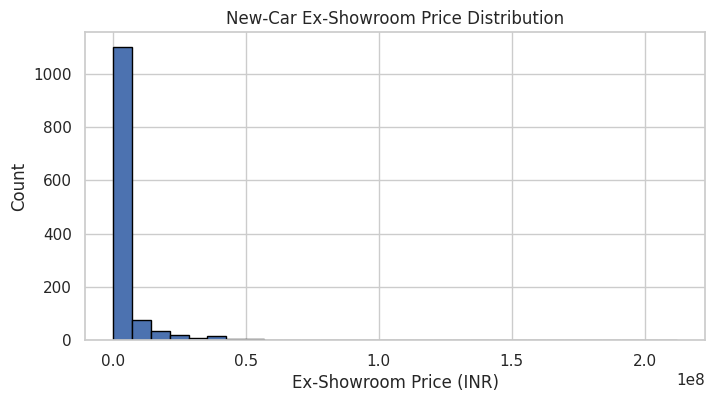

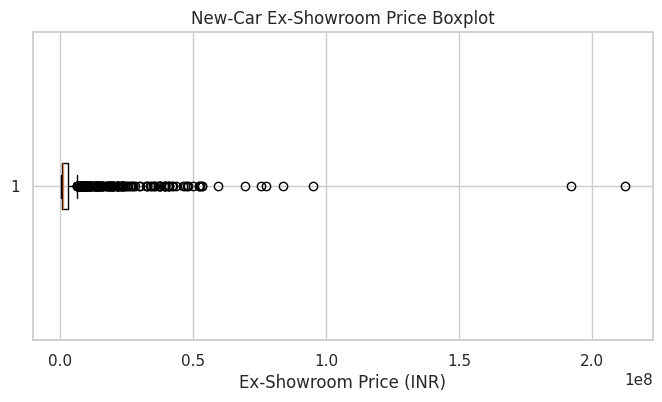

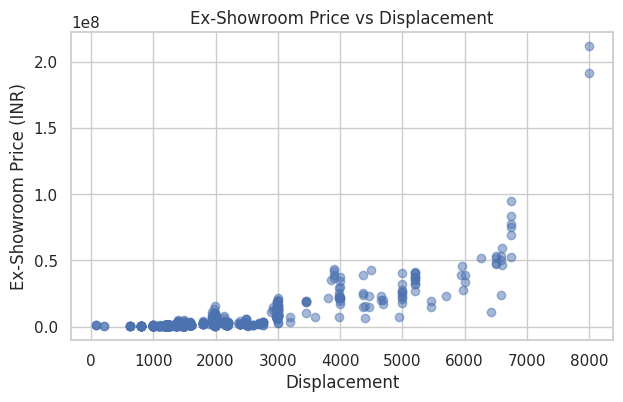

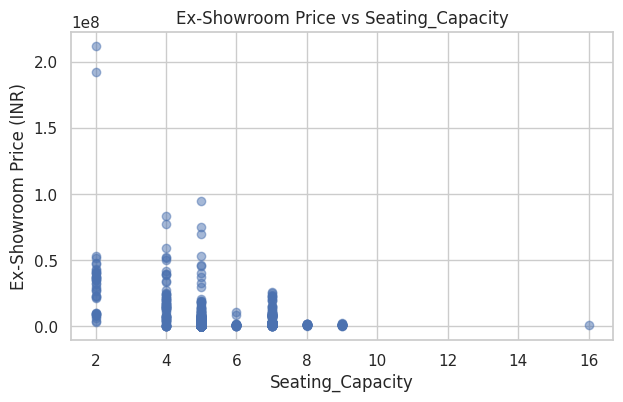

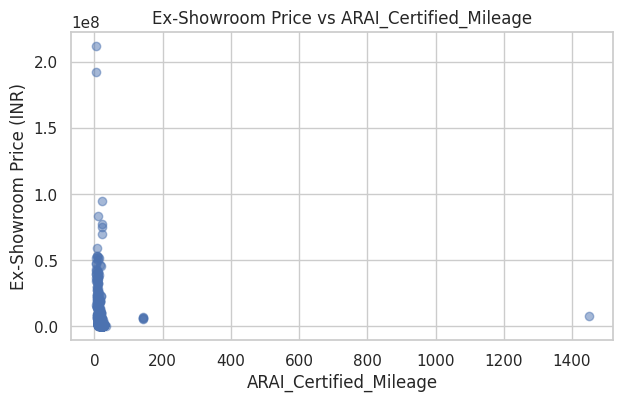

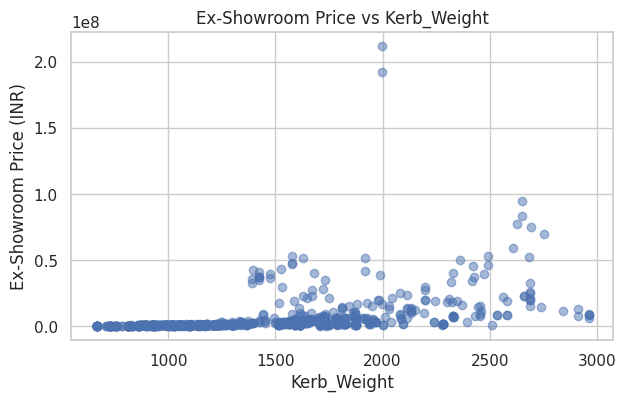

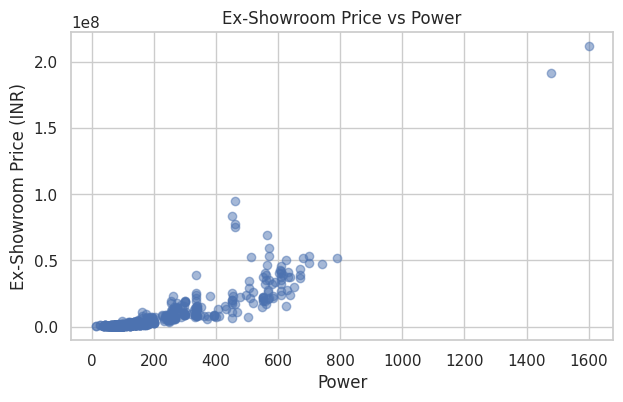

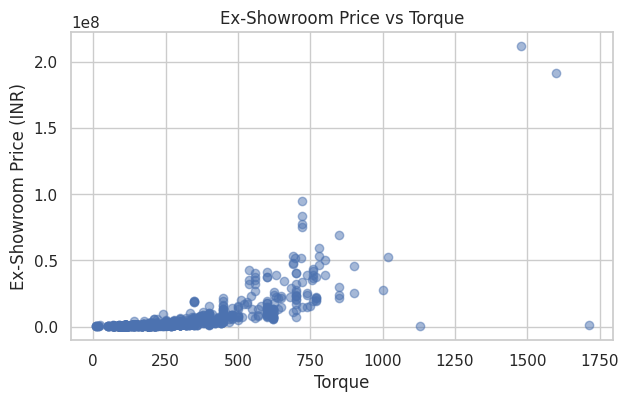

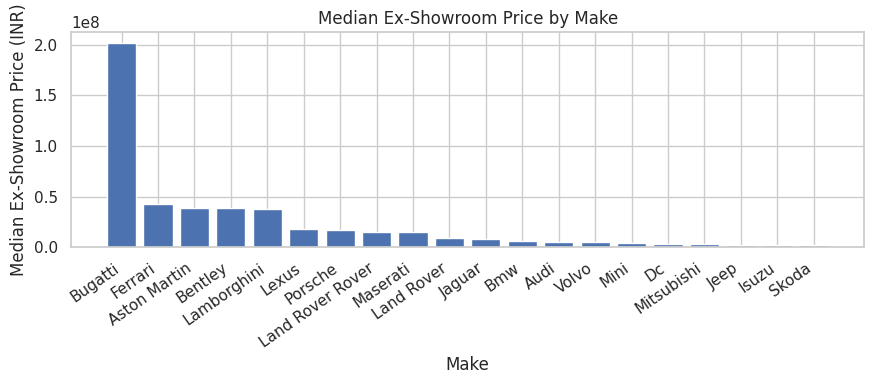

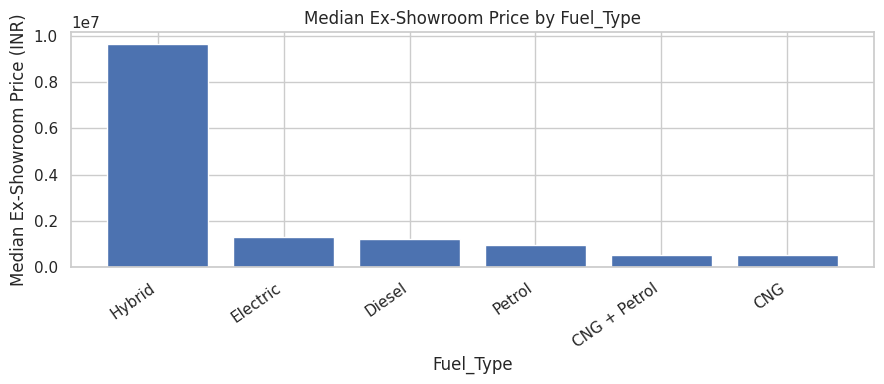

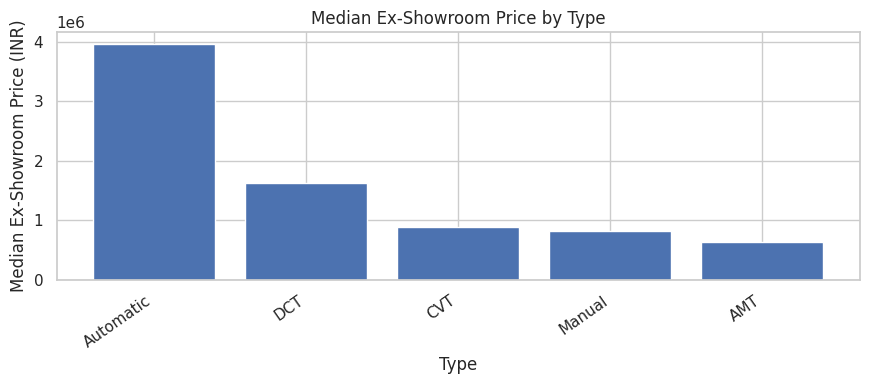

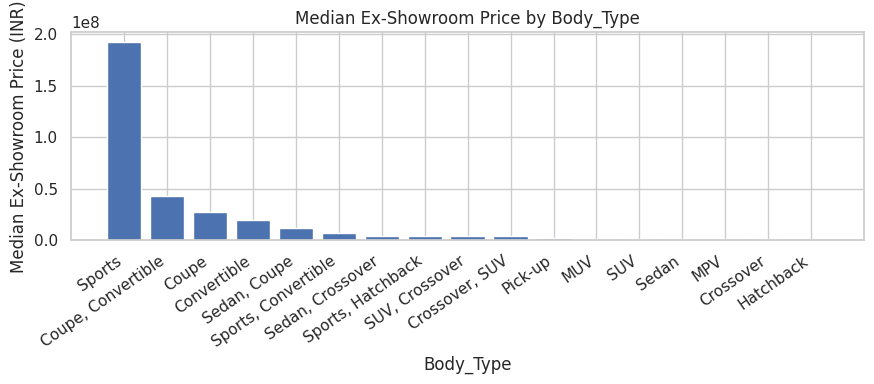

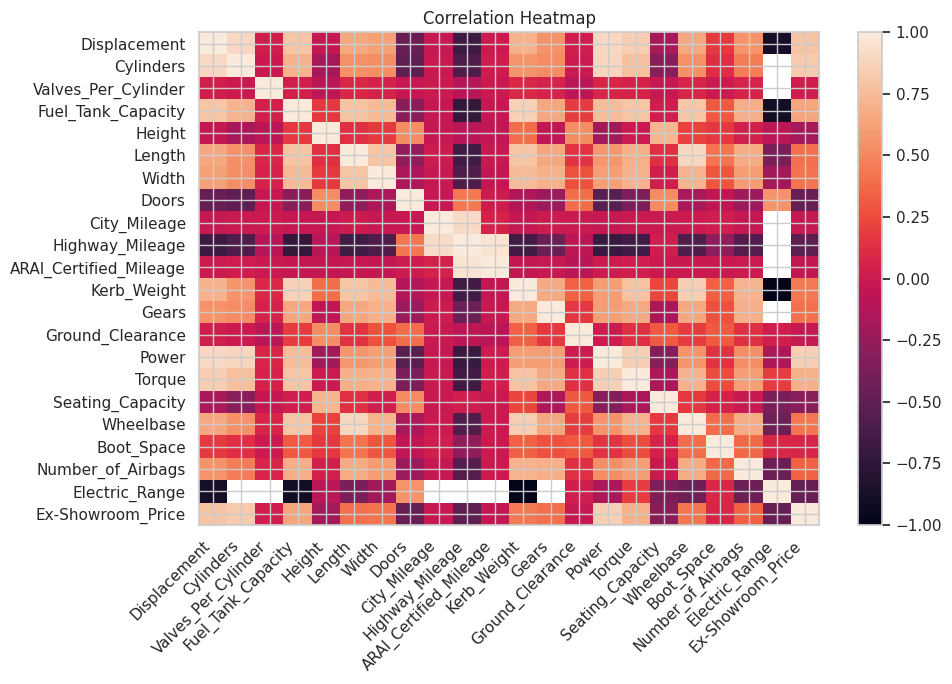

In [4]:
# Histogram of new-car ex-showroom prices
plt.figure(figsize=(8, 4))
plt.hist(df[target], bins=30, edgecolor="black")
plt.title("New-Car Ex-Showroom Price Distribution")
plt.xlabel("Ex-Showroom Price (INR)")
plt.ylabel("Count")
plt.show()

# Boxplot of new-car ex-showroom prices
plt.figure(figsize=(8, 4))
plt.boxplot(df[target].dropna(), vert=False)
plt.title("New-Car Ex-Showroom Price Boxplot")
plt.xlabel("Ex-Showroom Price (INR)")
plt.show()

# Scatterplots for available numerical car specifications
for feature in ["Displacement", "Seating_Capacity", "ARAI_Certified_Mileage",
                "Kerb_Weight", "Power", "Torque"]:
    if feature in numeric_features and df[feature].notna().sum() >= 3:
        plt.figure(figsize=(7, 4))
        plt.scatter(df[feature], df[target], alpha=0.5)
        plt.title(f"Ex-Showroom Price vs {feature}")
        plt.xlabel(feature)
        plt.ylabel("Ex-Showroom Price (INR)")
        plt.show()

# Compare median prices by available categories
for feature in ["Make", "Fuel_Type", "Type", "Body_Type"]:
    if feature in df.columns:
        category_prices = (
            df.groupby(feature)[target].median()
            .sort_values(ascending=False).head(20)
        )
        plt.figure(figsize=(9, 4))
        plt.bar(category_prices.index.astype(str), category_prices.values)
        plt.title(f"Median Ex-Showroom Price by {feature}")
        plt.xlabel(feature)
        plt.ylabel("Median Ex-Showroom Price (INR)")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

# Correlation heatmap for numerical features
correlation_columns = numeric_features + [target]
correlation = df[correlation_columns].corr()
plt.figure(figsize=(10, 7))
plt.imshow(correlation, aspect="auto", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45, ha="right")
plt.yticks(range(len(correlation.index)), correlation.index)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 5. Probability distributions, sampling, and CLT

**What we use**
- Histogram: checks the observed new-car ex-showroom price distribution.
- `np.random.uniform()` and `np.random.binomial()`: demonstrate example probability distributions.
- Random sampling: selects smaller samples from the car records.
- Central Limit Theorem (CLT): repeated sample means tend to form an approximately normal distribution under suitable conditions.

**Important:** the uniform and binomial values below are simulations used only to demonstrate probability distributions. They are not actual car dataset values.


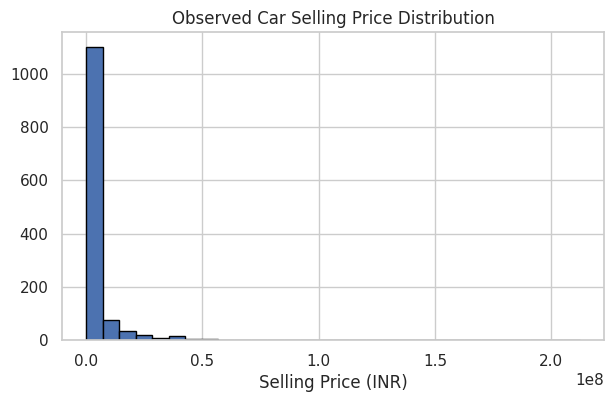

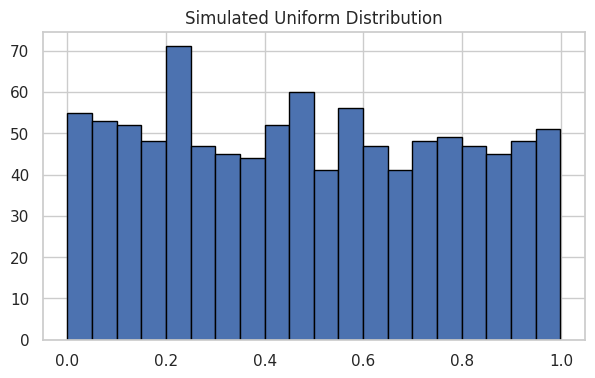

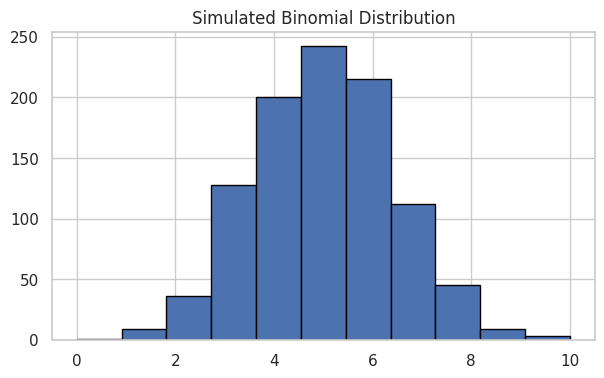

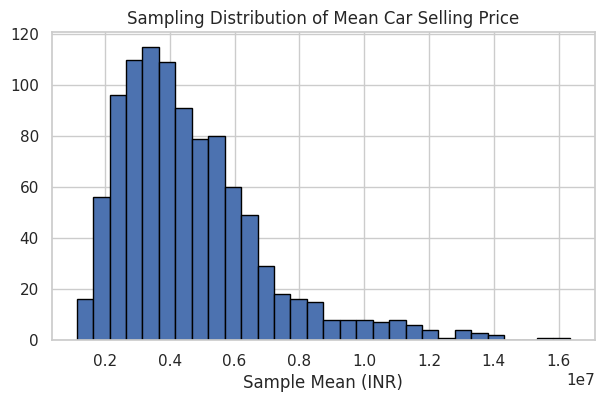

In [5]:
# Observed car selling-price distribution
plt.figure(figsize=(7, 4))
plt.hist(df[target], bins=30, edgecolor="black")
plt.title("Observed Car Selling Price Distribution")
plt.xlabel("Selling Price (INR)")
plt.show()

# Simulated uniform distribution (demonstration only)
uniform_data = np.random.uniform(low=0, high=1, size=1000)
plt.figure(figsize=(7, 4))
plt.hist(uniform_data, bins=20, edgecolor="black")
plt.title("Simulated Uniform Distribution")
plt.show()

# Simulated binomial distribution (demonstration only)
binomial_data = np.random.binomial(n=10, p=0.5, size=1000)
plt.figure(figsize=(7, 4))
plt.hist(binomial_data, bins=11, edgecolor="black")
plt.title("Simulated Binomial Distribution")
plt.show()

# CLT: repeated samples from car selling prices
sample_means = []
for i in range(1000):
    sample = df[target].sample(n=min(30, len(df)), replace=True)
    sample_means.append(sample.mean())

plt.figure(figsize=(7, 4))
plt.hist(sample_means, bins=30, edgecolor="black")
plt.title("Sampling Distribution of Mean Car Selling Price")
plt.xlabel("Sample Mean (INR)")
plt.show()

## 6. Sampling techniques and standard error

**What we use**
- Simple random sampling: each new-car variant record has a chance to be selected.
- Stratified sampling: samples separately from groups. Here, fuel types are used as strata.
- Standard error (SE): estimates how much a sample mean varies from sample to sample.

**What this section does:** demonstrates random and fuel-stratified samples, then calculates the standard error of the mean new-car ex-showroom price.


In [6]:
# Simple random sample
simple_sample = df.sample(n=min(100, len(df)), random_state=42)
print("Simple random sample size:", len(simple_sample))
display(simple_sample.head())

# Stratified sample by fuel type
if "Fuel_Type" in df.columns:
    stratified_sample = (
        df.groupby("Fuel_Type", group_keys=False)
          .apply(lambda group: group.sample(n=min(20, len(group)), random_state=42))
          .reset_index(drop=True)
    )
    print("Fuel-stratified sample size:", len(stratified_sample))
    display(stratified_sample.head())
else:
    print("Fuel_Type column is not available; stratified sampling was skipped.")

standard_error = stats.sem(df[target])
print("Standard error of mean new-car ex-showroom price:", round(standard_error, 2), "INR")


Simple random sample size: 100


,Make,Model,Variant,Ex-Showroom_Price,Displacement,Cylinders,Valves_Per_Cylinder,Drivetrain,Cylinder_Configuration,Emission_Norm,...,Leather_Wrapped_Steering,Automatic_Headlamps,Engine_Type,ASR_/_Traction_Control,Cruise_Control,USB_Ports,Heads-Up_Display,Welcome_Lights,Battery,Electric_Range
101,Nissan,Micra Active,Xl,525021,1198.0,3.0,12.0,FWD (Front Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
51,Hyundai,Santro,Sportz Mt Cng,578990,1086.0,4.0,4.0,FWD (Front Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
76,Maruti Suzuki,Ignis,Zeta 1.2 Mt,583320,1197.0,4.0,4.0,FWD (Front Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
644,Mahindra,Tuv300 Plus,P8,1142157,2179.0,3.0,4.0,RWD (Rear Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
425,Maruti Suzuki,Swift,Zdi,757000,1248.0,4.0,4.0,FWD (Front Wheel Drive),In-line,BS IV,...,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Fuel-stratified sample size: 91


/tmp/ipykernel_1126/3248286440.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.sample(n=min(20, len(group)), random_state=42))


,Make,Model,Variant,Ex-Showroom_Price,Displacement,Cylinders,Valves_Per_Cylinder,Drivetrain,Cylinder_Configuration,Emission_Norm,...,Leather_Wrapped_Steering,Automatic_Headlamps,Engine_Type,ASR_/_Traction_Control,Cruise_Control,USB_Ports,Heads-Up_Display,Welcome_Lights,Battery,Electric_Range
0,Tata,Nano Genx,Emax Xm,296661,624.0,2.0,2.0,RWD (Rear Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Maruti Suzuki,Eeco,5 Str With Ac+Htr Cng,466057,1196.0,4.0,4.0,RWD (Rear Wheel Drive),In-line,BS 6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Hyundai,Santro,Magna Mt Cng,547990,1086.0,4.0,4.0,FWD (Front Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Maruti Suzuki R,Wagon,Lxi Cng,500500,998.0,3.0,4.0,FWD (Front Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Hyundai,Grand I10,1.2 Kappa Vtvt Magna Cng,653452,1197.0,4.0,4.0,FWD (Front Wheel Drive),In-line,BS IV,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Standard error of mean new-car ex-showroom price: 340060.43 INR


## 7. Confidence interval for the mean new-car ex-showroom price

**What we use**
- `stats.t.interval()`: calculates a confidence interval using the t-distribution.
- `stats.sem()`: calculates the standard error.

**What this section does:** estimates a 95% confidence interval for the mean ex-showroom price based on the dataset.

This interval estimates uncertainty around the population mean. It does not mean that 95% of individual car prices fall inside this interval.


In [7]:
confidence = 0.95
mean_price = df[target].mean()
standard_error = stats.sem(df[target])

ci_low, ci_high = stats.t.interval(
    confidence,
    df=len(df) - 1,
    loc=mean_price,
    scale=standard_error
)

print(f"Mean car selling price: ₹{mean_price:,.2f}")
print(f"95% confidence interval: ₹{ci_low:,.2f} to ₹{ci_high:,.2f}")

Mean car selling price: ₹4,596,537.89
95% confidence interval: ₹3,929,398.38 to ₹5,263,677.39


## 8. Hypothesis tests (significance level α = 0.05)

**What we use**
- One-sample t-test: compares the mean new-car ex-showroom price with an editable reference price.
- Independent two-sample t-test: compares mean prices for manual and automatic cars.
- One-way ANOVA: compares mean prices across fuel types.
- Chi-square test of independence: checks association between fuel type and transmission type.

**How to read the result:** if the p-value is below 0.05, reject the null hypothesis for that test. Statistical significance does not automatically mean that the difference is practically important.


In [8]:
alpha = 0.05

# A. One-sample t-test: compare mean ex-showroom price with a reference price
reference_price = 1000000  # Editable reference price in INR
t_stat, p_value = stats.ttest_1samp(df[target], popmean=reference_price)

print("ONE-SAMPLE T-TEST")
print(f"H0: Mean new-car ex-showroom price = ₹{reference_price:,.0f}")
print(f"t-statistic = {t_stat:.3f}, p-value = {p_value:.5f}")
print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

# B. Independent t-test: compare manual and automatic transmission prices
if "Type" in df.columns:
    manual_prices = df.loc[df["Type"].astype(str).str.contains("manual", case=False, na=False), target]
    automatic_prices = df.loc[df["Type"].astype(str).str.contains("automatic|amt|cvt|dct", case=False, na=False), target]

    if len(manual_prices) >= 2 and len(automatic_prices) >= 2:
        t_stat, p_value = stats.ttest_ind(
            manual_prices, automatic_prices, equal_var=False
        )
        print("\nINDEPENDENT TWO-SAMPLE T-TEST")
        print("H0: Mean prices are equal for manual and automatic cars.")
        print(f"t-statistic = {t_stat:.3f}, p-value = {p_value:.5f}")
        print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")
    else:
        print("\nNot enough manual/automatic records for the independent t-test.")

# C. One-way ANOVA: compare prices across fuel types
if "Fuel_Type" in df.columns:
    fuel_groups = [
        group[target].dropna()
        for _, group in df.groupby("Fuel_Type")
        if group[target].notna().sum() >= 2
    ]
    if len(fuel_groups) >= 2:
        f_stat, p_value = stats.f_oneway(*fuel_groups)
        print("\nONE-WAY ANOVA")
        print("H0: Mean new-car prices are equal across fuel types.")
        print(f"F-statistic = {f_stat:.3f}, p-value = {p_value:.5f}")
        print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

# D. Chi-square test: fuel type and transmission type
if "Fuel_Type" in df.columns and "Type" in df.columns:
    contingency = pd.crosstab(df["Fuel_Type"], df["Type"])
    if contingency.shape[0] >= 2 and contingency.shape[1] >= 2:
        chi2, p_value, dof, expected = stats.chi2_contingency(contingency)
        print("\nCHI-SQUARE TEST OF INDEPENDENCE")
        print("H0: Fuel type and transmission type are independent.")
        print(f"Chi-square = {chi2:.3f}, p-value = {p_value:.5f}")
        print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")


ONE-SAMPLE T-TEST
H0: Mean new-car ex-showroom price = ₹1,000,000
t-statistic = 10.576, p-value = 0.00000
Decision: Reject H0

INDEPENDENT TWO-SAMPLE T-TEST
H0: Mean prices are equal for manual and automatic cars.
t-statistic = -11.425, p-value = 0.00000
Decision: Reject H0

ONE-WAY ANOVA
H0: Mean new-car prices are equal across fuel types.
F-statistic = 7.179, p-value = 0.00000
Decision: Reject H0

CHI-SQUARE TEST OF INDEPENDENCE
H0: Fuel type and transmission type are independent.
Chi-square = 76.832, p-value = 0.00000
Decision: Reject H0


## 9. Correlation and significance tests

**What we use**
- Pearson correlation: measures a linear relationship between two numerical variables.
- Spearman correlation: measures a monotonic relationship using ranks.
- Correlation p-value: tests whether the observed correlation differs from zero.

**What this section does:** checks relationships between available numerical car specifications and new-car ex-showroom price. Correlation does not prove causation.


In [9]:
numeric_predictors = [
    col for col in numeric_features
    if df[col].notna().sum() >= 3 and df[col].nunique(dropna=True) > 1
]

print("Pearson correlation matrix:")
display(df[numeric_predictors + [target]].corr(method="pearson"))

print("\nCovariance matrix:")
display(df[numeric_predictors + [target]].cov())

for x_col in numeric_predictors:
    pair = df[[x_col, target]].dropna()
    if len(pair) >= 3 and pair[x_col].nunique() > 1 and pair[target].nunique() > 1:
        pearson_r, pearson_p = stats.pearsonr(pair[x_col], pair[target])
        spearman_r, spearman_p = stats.spearmanr(pair[x_col], pair[target])
        print(f"\n{x_col} vs {target}")
        print(f"Pearson r = {pearson_r:.3f}, p-value = {pearson_p:.5f}")
        print(f"Spearman rho = {spearman_r:.3f}, p-value = {spearman_p:.5f}")

Pearson correlation matrix:


,Displacement,Cylinders,Valves_Per_Cylinder,Fuel_Tank_Capacity,Height,Length,Width,Doors,City_Mileage,Highway_Mileage,...,Gears,Ground_Clearance,Power,Torque,Seating_Capacity,Wheelbase,Boot_Space,Number_of_Airbags,Electric_Range,Ex-Showroom_Price
Displacement,1.000000,0.898620,0.034341,0.798744,-0.025309,0.654299,0.622096,-0.474678,-0.018312,-0.678459,...,0.549931,0.033733,0.901419,0.846067,-0.162146,0.650893,0.175074,0.562368,-0.878804,0.794293
Cylinders,0.898620,1.000000,-0.000935,0.707084,-0.169733,0.543789,0.531906,-0.507423,-0.011150,-0.588081,...,0.526954,0.001497,0.887790,0.777960,-0.318495,0.541809,0.123081,0.458069,NaN,0.820758
Valves_Per_Cylinder,0.034341,-0.000935,1.000000,0.046025,-0.072332,0.083042,0.047936,-0.029962,0.007626,-0.098206,...,0.059221,-0.077038,0.072206,0.049849,-0.024687,0.072460,0.003968,0.068139,NaN,0.030392
Fuel_Tank_Capacity,0.798744,0.707084,0.046025,1.000000,0.167254,0.795217,0.744368,-0.305433,-0.027185,-0.723665,...,0.655751,0.182098,0.761299,0.803971,0.028095,0.803291,0.307351,0.684106,-0.891089,0.643359
Height,-0.025309,-0.169733,-0.072332,0.167254,1.000000,0.131762,0.173644,0.527628,-0.025271,-0.088688,...,-0.052071,0.530243,-0.193673,0.007043,0.724973,0.214471,0.169054,0.039073,-0.075032,-0.187472
Length,0.654299,0.543789,0.083042,0.795217,0.131762,1.000000,0.796956,-0.265952,0.010856,-0.658735,...,0.655451,0.146347,0.573281,0.694231,0.127099,0.894219,0.421306,0.675287,-0.372209,0.401162
Width,0.622096,0.531906,0.047936,0.744368,0.173644,0.796956,1.000000,-0.152151,-0.018397,-0.580970,...,0.702760,0.275326,0.614409,0.710800,0.031980,0.718685,0.295408,0.597562,-0.203051,0.420144
Doors,-0.474678,-0.507423,-0.029962,-0.305433,0.527628,-0.265952,-0.152151,1.000000,-0.022538,0.430568,...,-0.230673,0.386074,-0.535678,-0.369424,0.521476,-0.156802,-0.047242,-0.220540,0.557499,-0.461746
City_Mileage,-0.018312,-0.011150,0.007626,-0.027185,-0.025271,0.010856,-0.018397,-0.022538,1.000000,0.915010,...,0.008105,-0.010483,-0.021029,-0.012550,-0.010685,0.000348,0.030987,-0.030766,NaN,-0.016084
Highway_Mileage,-0.678459,-0.588081,-0.098206,-0.723665,-0.088688,-0.658735,-0.580970,0.430568,0.915010,1.000000,...,-0.450154,-0.070120,-0.689104,-0.655845,0.030897,-0.576685,-0.277457,-0.552552,NaN,-0.507508



Covariance matrix:


,Displacement,Cylinders,Valves_Per_Cylinder,Fuel_Tank_Capacity,Height,Length,Width,Doors,City_Mileage,Highway_Mileage,...,Gears,Ground_Clearance,Power,Torque,Seating_Capacity,Wheelbase,Boot_Space,Number_of_Airbags,Electric_Range,Ex-Showroom_Price
Displacement,1.130293e+06,1.584871e+03,30.766443,1.336227e+04,-4.266856e+03,3.315026e+05,1.004590e+05,-3.786977e+02,-2.032105e+04,-3.945897e+03,...,6.900362e+02,1.083289e+03,1.306709e+05,1.666423e+05,-1.975253e+02,1.459379e+05,3.220302e+04,1.515516e+03,-5.633443e+04,1.029289e+10
Cylinders,1.584871e+03,2.758778e+00,-0.001266,1.851383e+01,-4.526811e+01,4.321503e+02,1.344147e+02,-6.398230e-01,-1.859563e+01,-5.191709e+00,...,1.037667e+00,7.505062e-02,2.046088e+02,2.419397e+02,-6.171131e-01,1.899402e+02,3.560723e+01,1.966225e+00,0.000000e+00,1.691277e+07
Valves_Per_Cylinder,3.076644e+01,-1.266046e-03,0.695161,6.374146e-01,-9.557126e+00,3.367433e+01,6.165158e+00,-1.899721e-02,3.853152e+00,-2.455677e-01,...,6.080058e-02,-1.791363e+00,8.397054e+00,7.860649e+00,-2.313896e-02,1.295957e+01,6.233289e-01,1.440958e-01,0.000000e+00,3.173720e+05
Fuel_Tank_Capacity,1.336227e+04,1.851383e+01,0.637415,2.708972e+02,4.316683e+02,6.131990e+03,1.816164e+03,-3.761973e+00,-4.476224e+02,-6.068441e+01,...,1.233321e+01,9.267358e+01,1.563152e+03,2.339020e+03,5.305001e-01,2.709134e+03,8.722972e+02,2.882484e+01,-1.855220e+03,9.662996e+07
Height,-4.266856e+03,-4.526811e+01,-9.557126,4.316683e+02,2.493755e+04,9.918834e+03,4.093558e+03,6.206108e+01,-4.027993e+03,-7.390592e+01,...,-9.936795e+00,2.538516e+03,-4.171832e+03,2.056318e+02,1.310435e+02,7.128207e+03,3.945783e+03,1.455986e+01,-7.019150e+02,-3.597213e+08
Length,3.315026e+05,4.321503e+02,33.674333,6.131990e+03,9.918834e+03,2.271599e+05,5.756677e+04,-9.475077e+01,4.869600e+03,-1.589327e+03,...,3.571787e+02,2.156988e+03,3.732351e+04,6.137920e+04,6.939160e+01,8.912562e+04,3.601994e+04,7.922186e+02,-2.490424e+04,2.322562e+09
Width,1.004590e+05,1.344147e+02,6.165158,1.816164e+03,4.093558e+03,5.756677e+04,2.278058e+04,-1.706752e+01,-2.424777e+03,-4.106111e+02,...,1.193876e+02,1.209702e+03,1.269942e+04,1.997912e+04,5.322462e+00,2.288082e+04,7.910242e+03,2.249273e+02,-3.842085e+03,7.735602e+08
Doors,-3.786977e+02,-6.398230e-01,-0.018997,-3.761973e+00,6.206108e+01,-9.475077e+01,-1.706752e+01,5.592289e-01,-1.730304e+01,1.686424e+00,...,-2.024932e-01,8.435558e+00,-5.458760e+01,-5.093511e+01,4.467651e-01,-2.432162e+01,-6.339452e+00,-4.188631e-01,3.634313e+01,-4.197639e+06
City_Mileage,-2.032105e+04,-1.859563e+01,3.853152,-4.476224e+02,-4.027993e+03,4.869600e+03,-2.424777e+03,-1.730304e+01,9.388371e+05,2.348862e+01,...,8.367788e+00,-2.980355e+02,-2.749493e+03,-2.138246e+03,-1.304338e+01,7.068992e+01,5.634569e+03,-7.835351e+01,0.000000e+00,-1.669225e+08
Highway_Mileage,-3.945897e+03,-5.191709e+00,-0.245568,-6.068441e+01,-7.390592e+01,-1.589327e+03,-4.106111e+02,1.686424e+00,2.348862e+01,2.421322e+01,...,-2.366547e+00,-1.046876e+01,-4.698509e+02,-6.033209e+02,1.864904e-01,-6.596059e+02,-2.175023e+02,-6.936176e+00,NaN,-2.957405e+07



Displacement vs Ex-Showroom_Price
Pearson r = 0.794, p-value = 0.00000
Spearman rho = 0.877, p-value = 0.00000

Cylinders vs Ex-Showroom_Price
Pearson r = 0.821, p-value = 0.00000
Spearman rho = 0.731, p-value = 0.00000

Valves_Per_Cylinder vs Ex-Showroom_Price
Pearson r = 0.030, p-value = 0.29812
Spearman rho = 0.123, p-value = 0.00002

Fuel_Tank_Capacity vs Ex-Showroom_Price
Pearson r = 0.643, p-value = 0.00000
Spearman rho = 0.853, p-value = 0.00000

Height vs Ex-Showroom_Price
Pearson r = -0.187, p-value = 0.00000
Spearman rho = -0.003, p-value = 0.92158

Length vs Ex-Showroom_Price
Pearson r = 0.401, p-value = 0.00000
Spearman rho = 0.865, p-value = 0.00000

Width vs Ex-Showroom_Price
Pearson r = 0.420, p-value = 0.00000
Spearman rho = 0.865, p-value = 0.00000

Doors vs Ex-Showroom_Price
Pearson r = -0.462, p-value = 0.00000
Spearman rho = -0.298, p-value = 0.00000

City_Mileage vs Ex-Showroom_Price
Pearson r = -0.016, p-value = 0.66636
Spearman rho = -0.605, p-value = 0.00000

H

## 10. Prepare data for machine learning

**What we use**
- `train_test_split()`: reserves 20% of records for testing.
- `ColumnTransformer`: applies different preprocessing to numerical and categorical columns.
- `SimpleImputer`: fills missing feature values inside the model pipeline.
- `StandardScaler`: scales numerical features.
- `OneHotEncoder`: converts categories such as brand, fuel type, transmission type and body type into numeric indicator columns.
- `Pipeline`: combines preprocessing and a regression model.

**Why:** the same preprocessing is applied consistently during training and prediction.


In [10]:
X = df[features].copy()
y = df[target].copy()

# Keep the same feature types selected during data cleaning.
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)


Training data: (1020, 30)
Testing data: (256, 30)


## 11. Train and compare regression models

**What we use**
- Linear Regression: models a linear relationship between car specifications and price.
- Ridge Regression: linear regression with L2 regularization.
- Lasso Regression: linear regression with L1 regularization.
- Decision Tree: learns rule-based splits.
- Random Forest: combines multiple decision trees.
- MAE: average absolute prediction error, in INR.
- MSE: average squared prediction error.
- RMSE: gives more weight to larger errors, in INR.
- R²: measures the proportion of target-price variation explained by the model.

All models use the same training and testing data.

In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=12, random_state=42, n_jobs=-1
    )
}

results = []
trained_models = {}
predictions_by_model = {}

for name, regressor in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", regressor)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions_by_model[name] = predictions

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2 Score"]
)

print("MODEL COMPARISON")
display(results_df.round(2).sort_values("R2 Score", ascending=False))

MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2 Score
3,Decision Tree,935334.29,9.929937e+12,3151180.20,0.95
4,Random Forest,783042.22,1.122660e+13,3350612.14,0.94
1,Ridge Regression,1707850.34,1.292605e+13,3595280.95,0.93
0,Linear Regression,1830025.15,2.292713e+13,4788228.16,0.88
2,Lasso Regression,1991447.13,3.169035e+13,5629418.13,0.84


## 12. Paired t-test: actual vs predicted new-car prices

**What we use:** `stats.ttest_rel()` performs a paired t-test.

**Why paired?** Each actual test price is paired with the prediction for the same car variant. This test checks whether the average difference between actual and predicted ex-showroom prices is statistically distinguishable from zero.

It does not replace MAE/RMSE, and a non-significant result does not prove that the model is accurate. Always consider the error metrics as well.


In [12]:
best_index = results_df["R2 Score"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions_by_model[best_model_name]

t_stat, p_value = stats.ttest_rel(
    y_test.to_numpy(),
    best_predictions
)

print("PAIRED T-TEST: Actual vs Predicted Car Price")
print(f"Mean actual price: ₹{y_test.mean():,.2f}")
print(f"Mean predicted price: ₹{np.mean(best_predictions):,.2f}")
print(f"t-statistic = {t_stat:.3f}, p-value = {p_value:.5f}")
print(
    "Decision:",
    "Reject H0: mean paired difference is not zero"
    if p_value < alpha
    else "Fail to reject H0: insufficient evidence of a mean difference"
)

PAIRED T-TEST: Actual vs Predicted Car Price
Mean actual price: ₹4,166,582.38
Mean predicted price: ₹4,394,532.69
t-statistic = -1.158, p-value = 0.24787
Decision: Fail to reject H0: insufficient evidence of a mean difference


## 13. Best model selection and save the model

**What we use**
- Highest R² score: selects the model that explains the largest proportion of target-price variation in the test results.
- `joblib.dump()`: saves the complete fitted pipeline, including preprocessing and the model.
- JSON and CSV files: store feature names and the cleaned dataset for later use.

**What this section does:** identifies the best model from the comparison table and creates files that can be reused by a prediction application.

In [13]:
best_index = results_df["R2 Score"].idxmax()
best_model_name = results_df.loc[best_index, "Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best R2 Score:", round(results_df.loc[best_index, "R2 Score"], 4))

# Save the complete fitted pipeline (preprocessing + regression model).
# The Streamlit app will load this exact file.
joblib.dump(best_model, "new_car_price_model.pkl")

# Save the selected model name.
with open("best_car_model_name.txt", "w", encoding="utf-8") as file:
    file.write(best_model_name)

# Save the exact feature order used during training.
with open("car_model_features.json", "w", encoding="utf-8") as file:
    json.dump(features, file, indent=4)

# Save a Streamlit-friendly input configuration.
feature_config = {}

for col in numeric_features:
    values = X[col].dropna()
    feature_config[col] = {
        "type": "number",
        "default": float(values.median()),
        "min": float(values.min()),
        "max": float(values.max())
    }

for col in categorical_features:
    options = sorted(X[col].dropna().astype(str).unique().tolist())
    feature_config[col] = {
        "type": "category",
        "options": options,
        "default": options[0] if options else "Unknown"
    }

with open("car_feature_config.json", "w", encoding="utf-8") as file:
    json.dump(feature_config, file, indent=4)

# Save the scikit-learn version to prevent the .pkl version mismatch.
with open("sklearn_version.txt", "w", encoding="utf-8") as file:
    file.write(sklearn.__version__)

# Save only selected model features and the target.
df[features + [target]].to_csv("cars_cleaned.csv", index=False)
results_df.to_csv("car_model_comparison.csv", index=False)

print("\nFiles created successfully:")
print("new_car_price_model.pkl")
print("best_car_model_name.txt")
print("car_model_features.json")
print("car_feature_config.json")
print("sklearn_version.txt")
print("cars_cleaned.csv")
print("car_model_comparison.csv")


Best Model: Decision Tree
Best R2 Score: 0.9485

Files created successfully:
new_car_price_model.pkl
best_car_model_name.txt
car_model_features.json
car_feature_config.json
sklearn_version.txt
cars_cleaned.csv
car_model_comparison.csv


## 14. Actual vs predicted graph and model performance

**What this section does:** visualizes the best model's predictions for new-car ex-showroom prices and compares the model scores. Points closer to the diagonal line indicate predictions closer to actual prices.


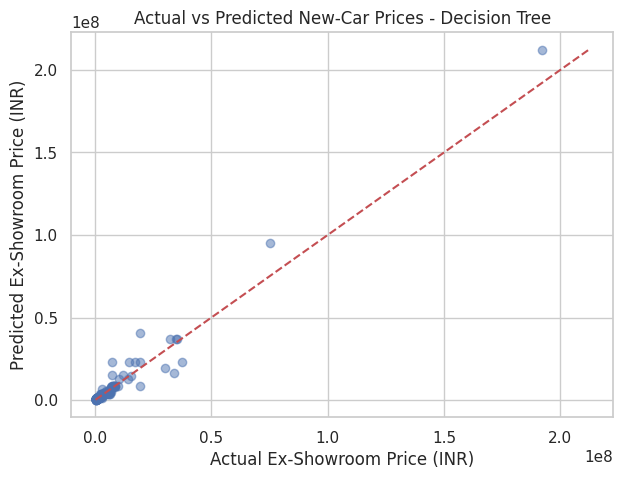

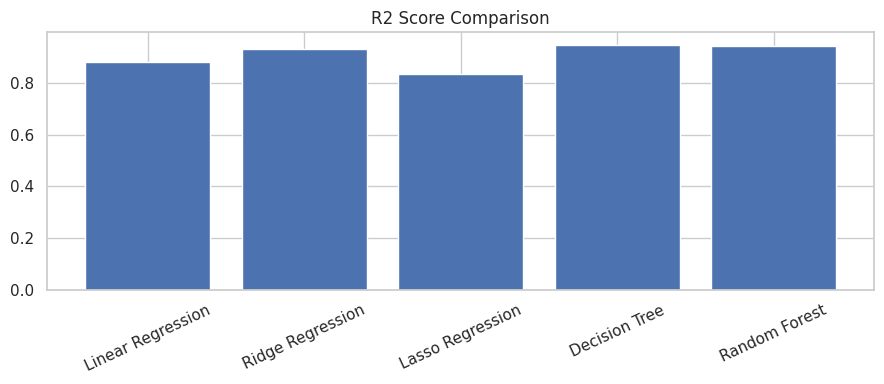

Best model performance:


,Model,MAE,MSE,RMSE,R2 Score
3,Decision Tree,935334.29,9.929937e+12,3151180.2,0.95


In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.5)
minimum = min(y_test.min(), np.min(best_predictions))
maximum = max(y_test.max(), np.max(best_predictions))
plt.plot([minimum, maximum], [minimum, maximum], "r--")
plt.xlabel("Actual Ex-Showroom Price (INR)")
plt.ylabel("Predicted Ex-Showroom Price (INR)")
plt.title(f"Actual vs Predicted New-Car Prices - {best_model_name}")
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("R2 Score Comparison")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print("Best model performance:")
display(results_df.loc[[best_index]].round(2))


## 15. Use the trained model in VS Code with Streamlit

The model is trained in Google Colab. The next section downloads the model and supporting files. Move the downloaded files into the same VS Code folder as `app.py`.

**Files needed by the updated Streamlit application:**
- `new_car_price_model.pkl` — trained preprocessing and prediction pipeline
- `car_feature_config.json` — feature names, numeric ranges and category choices for input controls
- `sklearn_version.txt` — exact scikit-learn version used in Colab
- `car_model_features.json` — exact feature order used during training
- `cars_cleaned.csv` — cleaned selected features and ex-showroom price
- `car_model_comparison.csv` — model evaluation results
- `best_car_model_name.txt` — selected model name

Do not use the old used-car model file. The new Streamlit app must load `new_car_price_model.pkl` and use `car_feature_config.json`.


## 16. Download trained model files from Google Colab

Run this cell after the training and evaluation sections have completed successfully. Download all files listed below and place them in the same VS Code folder as `app.py`.

The `sklearn_version.txt` file is important: install the same scikit-learn version in VS Code before loading the `.pkl` file.


In [15]:
from google.colab import files
import os

files_to_download = [
    "new_car_price_model.pkl",
    "best_car_model_name.txt",
    "car_model_features.json",
    "car_feature_config.json",
    "sklearn_version.txt",
    "cars_cleaned.csv",
    "car_model_comparison.csv"
]

for file_name in files_to_download:
    if os.path.exists(file_name):
        files.download(file_name)
    else:
        print("File not found:", file_name)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
print("Scikit-learn version used to train the model:", sklearn.__version__)
print("This version is also saved in sklearn_version.txt.")


Scikit-learn version used to train the model: 1.6.1
This version is also saved in sklearn_version.txt.


## 17. Final conclusion

This notebook uses the uploaded `cars_ds_final.csv` dataset of new-car models and variants. It analyzes the historical ex-showroom prices, performs descriptive and inferential statistical analysis, compares regression models, and exports the best fitted pipeline.

After running the notebook, record the actual dataset size, descriptive statistics, confidence interval, hypothesis-test decisions, and best regression model performance. The exported `new_car_price_model.pkl` contains the fitted preprocessing steps and regression model. Use the exact scikit-learn version saved in `sklearn_version.txt` when loading it in VS Code.

**Price interpretation:** the model estimates historical ex-showroom prices represented in this dataset. It does not provide current live dealer prices.
